EUROPEAN ROULETTE GAMBLER'S FALLACY CHECK
Theoretical P(win on any spin) = 0.4864864864864865
Theoretical P(loss on any spin) = 0.5135135135135135

THEORETICAL CONDITIONAL PROBABILITIES
-----------------------------------------------------------------

 n     P_Ln  P_Ln_and_Win  Conditional_P_Win
 1 0.513514      0.249817           0.486486
 2 0.263696      0.128285           0.486486
 3 0.135412      0.065876           0.486486
 5 0.035707      0.017371           0.486486
 7 0.009416      0.004581           0.486486
10 0.001275      0.000620           0.486486

MONTE CARLO CONDITIONAL-PROBABILITY CHECK
-----------------------------------------------------------------

 n  Observed_Losing_Streaks  Theoretical_P_Win  Simulated_P_Win_After_Losses  Difference  Standard_Error   Z_Score
 1                   513161           0.486486                      0.486407   -0.000080        0.000698 -0.114209
 2                   263884           0.486486                      0.487718    0.001232    

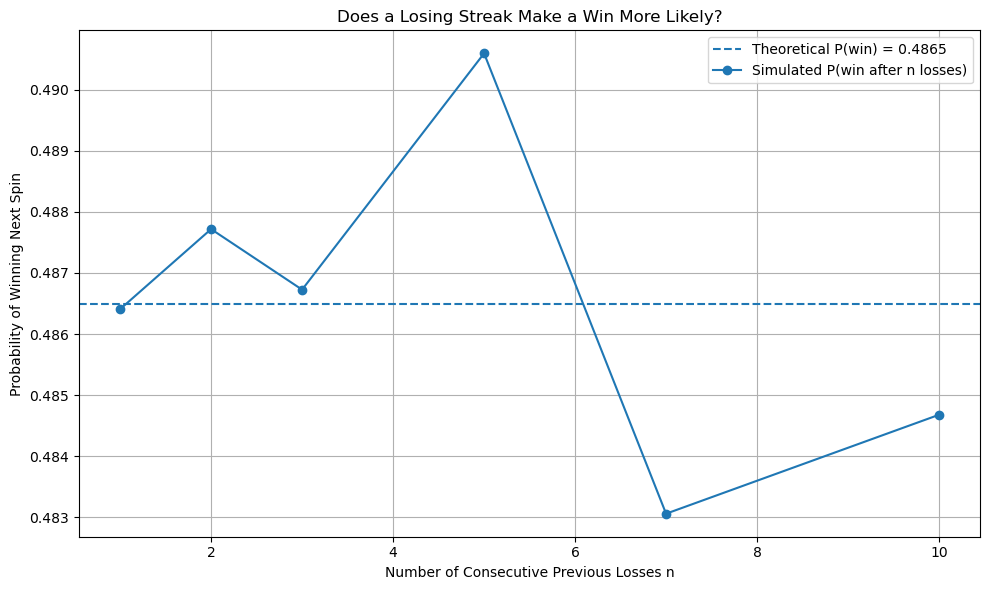

In [1]:
# ============================================================
# HOMEWORK 2.2 - PART II
# GAMBLER'S FALLACY VERIFICATION
#
# Standalone code
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# SETTINGS
# ============================================================

NUM_TRIALS = 1_000_000

SEED = 42


# Test several losing-streak lengths
streak_lengths = [
    1,
    2,
    3,
    5,
    7,
    10
]


# ============================================================
# EUROPEAN ROULETTE PARAMETERS
# ============================================================

p_win = 18 / 37

p_loss = 19 / 37


print("=" * 65)

print(
    "EUROPEAN ROULETTE GAMBLER'S FALLACY CHECK"
)

print("=" * 65)

print(
    "Theoretical P(win on any spin) =",
    p_win
)

print(
    "Theoretical P(loss on any spin) =",
    p_loss
)


# ============================================================
# THEORETICAL CHECK
# ============================================================

theory_results = []


for n in streak_lengths:

    p_Ln = (
        p_loss ** n
    )


    p_Ln_and_win = (
        p_Ln
        *
        p_win
    )


    conditional_probability = (
        p_Ln_and_win
        /
        p_Ln
    )


    theory_results.append({

        "n":
            n,

        "P_Ln":
            p_Ln,

        "P_Ln_and_Win":
            p_Ln_and_win,

        "Conditional_P_Win":
            conditional_probability

    })


theory_df = pd.DataFrame(
    theory_results
)


print()

print(
    "THEORETICAL CONDITIONAL PROBABILITIES"
)

print("-" * 65)

print()

print(
    theory_df.to_string(
        index=False
    )
)


# ============================================================
# MONTE CARLO VERIFICATION
#
# For every value of n:
#
# Generate NUM_TRIALS independent experiments.
#
# Each experiment contains:
#
# n previous spins
# +
# one next spin
#
# We then look only at experiments in which
# the first n spins were all losses.
# ============================================================

rng = np.random.default_rng(
    SEED
)


simulation_results = []


for n in streak_lengths:

    # Generate independent win/loss outcomes.
    #
    # True means win on red.
    #
    # Shape:
    #
    # NUM_TRIALS rows
    # n+1 spins per row

    spins = (
        rng.random(
            size=(
                NUM_TRIALS,
                n + 1
            )
        )
        <
        p_win
    )


    # First n spins must all be losses

    previous_losses = np.all(
        ~spins[:, :n],
        axis=1
    )


    # Outcome of spin n+1

    next_spin_win = spins[:, n]


    # Count streaks

    number_of_streaks = np.sum(
        previous_losses
    )


    # Count wins after those streaks

    wins_after_streak = np.sum(

        previous_losses
        &
        next_spin_win
    )


    # Conditional probability estimate

    simulated_conditional = (

        wins_after_streak
        /
        number_of_streaks
    )


    # Theoretical conditional probability

    theoretical_conditional = (
        p_win
    )


    # Standard error based on the number of
    # observed losing streaks

    standard_error = np.sqrt(

        theoretical_conditional

        *

        (
            1
            -
            theoretical_conditional
        )

        /

        number_of_streaks
    )


    difference = (
        simulated_conditional
        -
        theoretical_conditional
    )


    z_score = (
        difference
        /
        standard_error
    )


    simulation_results.append({

        "n":
            n,

        "Observed_Losing_Streaks":
            number_of_streaks,

        "Theoretical_P_Win":
            theoretical_conditional,

        "Simulated_P_Win_After_Losses":
            simulated_conditional,

        "Difference":
            difference,

        "Standard_Error":
            standard_error,

        "Z_Score":
            z_score

    })


simulation_df = pd.DataFrame(
    simulation_results
)


print()

print(
    "MONTE CARLO CONDITIONAL-PROBABILITY CHECK"
)

print("-" * 65)

print()

print(
    simulation_df.to_string(
        index=False
    )
)


# ============================================================
# AUTOMATIC VERIFICATION
# ============================================================

print()

print("=" * 65)

print(
    "AUTOMATIC VERIFICATION"
)

print("=" * 65)


all_pass = True


for _, row in simulation_df.iterrows():

    n = int(
        row["n"]
    )


    z = row[
        "Z_Score"
    ]


    if abs(z) < 4:

        print(
            f"PASS: n={n}: "
            "win probability after the losing streak "
            "agrees with ordinary win probability."
        )

    else:

        all_pass = False

        print(
            f"WARNING: n={n}: "
            "simulation differs from theory "
            "more than expected."
        )


if all_pass:

    print()

    print(
        "FINAL RESULT:"
    )

    print(
        "There is no numerical evidence that "
        "a losing streak increases the probability "
        "of winning the next spin."
    )


# ============================================================
# PLOT
# ============================================================

plt.figure(
    figsize=(10, 6)
)


plt.axhline(
    p_win,
    linestyle="--",
    label=(
        "Theoretical P(win) = "
        f"{p_win:.4f}"
    )
)


plt.plot(

    simulation_df["n"],

    simulation_df[
        "Simulated_P_Win_After_Losses"
    ],

    marker="o",

    label=(
        "Simulated P(win after n losses)"
    )
)


plt.xlabel(
    "Number of Consecutive Previous Losses n"
)


plt.ylabel(
    "Probability of Winning Next Spin"
)


plt.title(
    "Does a Losing Streak Make a Win More Likely?"
)


plt.grid(
    True
)


plt.legend()


plt.tight_layout()


plt.savefig(
    "gamblers_fallacy_conditional_probability.png",
    dpi=300
)


plt.show()